### Preparação

In [34]:
import subprocess

import subprocess

def run(*args):
    return subprocess.run(
        [str(arg) for arg in args],
        check=True,
    )

### Importar e Instalar Bibliotecas

In [35]:
import json
import subprocess
import sys
from pathlib import Path

# ============================================================
# Configuração
# ============================================================

EXPECTED_PYTHON = (3, 11, 13)

ENV_DIR = Path("/projects/.venvs/spark-py311")
ENV_PYTHON = ENV_DIR / "bin/python"
MARKER = ENV_DIR / "setup-completo.json"

KERNEL_NAME = "spark-py311"
KERNEL_DISPLAY_NAME = "Python 3.11 — Spark"

REDHAT_INDEX = (
    "https://packages.redhat.com/api/pypi/"
    "public-rhai/rhoai/3.5/cpu-ubi9/simple/"
)

PYPI_INDEX = "https://pypi.org/simple"

PACKAGES = [
    "kubeflow[spark]==0.3.0+rhaiv.3",
    "pyspark-connect==4.0.1",
    "zstandard",
    "ipykernel",
    "matplotlib",
]

# Mantém o formato do marcador usado nas células anteriores.
CONFIG = {
    "python_version": list(EXPECTED_PYTHON),
    "packages": PACKAGES,
    "pyarrow": "24.0.0",
    "setup_version": 1,
}

VALIDATE = """
import sys
from kubeflow.spark import SparkClient
import pyspark
import pandas
import pyarrow
import grpc
import zstandard
import ipykernel
import matplotlib

assert sys.version_info[:3] == (3, 11, 13), sys.version
assert pyspark.__version__ == "4.0.1", pyspark.__version__
assert pyarrow.__version__ == "24.0.0", pyarrow.__version__

print("Python:", sys.version.split()[0])
print("PySpark:", pyspark.__version__)
print("PyArrow:", pyarrow.__version__)
print("Imports validados.")
"""

# ============================================================
# Execução de comandos com mensagens de erro completas
# ============================================================

def run(*args):
    command = [str(arg) for arg in args]

    result = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    if result.stdout:
        print(result.stdout, end="")

    if result.returncode != 0:
        raise subprocess.CalledProcessError(
            result.returncode,
            command,
            output=result.stdout,
        )

    return result


# ============================================================
# Validar o interpretador atual
# ============================================================

if sys.version_info[:3] != EXPECTED_PYTHON:
    raise RuntimeError(
        "Esta preparação requer Python 3.11.13. "
        f"Kernel atual: {sys.version.split()[0]}"
    )


# ============================================================
# Reutilizar ou preparar o ambiente persistente
# ============================================================

if MARKER.exists():
    saved = json.loads(MARKER.read_text())

    if saved != CONFIG:
        raise RuntimeError(
            "O ambiente existente foi preparado com outra configuração. "
            "Use outro ENV_DIR e outro nome de kernel para uma nova versão."
        )

    print("Validando o ambiente persistente...")
    run(ENV_PYTHON, "-c", VALIDATE)

    print("\nAmbiente pronto. Nenhum pip install executado.")

else:
    ENV_DIR.parent.mkdir(parents=True, exist_ok=True)

    if not ENV_PYTHON.exists():
        print("Criando ambiente virtual no PVC...")
        run(sys.executable, "-m", "venv", ENV_DIR)

    # Pode existir uma instalação concluída sem marcador.
    # Se os imports já funcionarem, não instala novamente.
    probe = subprocess.run(
        [str(ENV_PYTHON), "-c", VALIDATE],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    if probe.returncode == 0:
        print(probe.stdout, end="")
        print("Dependências já disponíveis. Instalação dispensada.")

    else:
        print("Preparando dependências no ambiente persistente...")

        constraints = ENV_DIR / "constraints.txt"
        constraints.write_text("pyarrow==24.0.0\n")

        # Verifica versão e funcionamento do PyArrow.
        arrow_probe = subprocess.run(
            [
                str(ENV_PYTHON),
                "-c",
                (
                    "import pyarrow; "
                    "assert pyarrow.__version__ == '24.0.0'"
                ),
            ],
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        )

        if arrow_probe.returncode != 0:
            # Corrige também instalações anteriores com libthrift ausente.
            print("Instalando o wheel PyArrow 24.0.0 do PyPI...")

            run(
                ENV_PYTHON,
                "-m", "pip", "install",
                "--index-url", PYPI_INDEX,
                "--only-binary=:all:",
                "--no-deps",
                "--force-reinstall",
                "pyarrow==24.0.0",
            )

        # Bibliotecas auxiliares.
        run(
            ENV_PYTHON,
            "-m", "pip", "install",
            "--index-url", PYPI_INDEX,
            "--constraint", constraints,
            "zstandard",
            "ipykernel",
            "matplotlib",
        )

        # SDK Red Hat fixado; PyPI disponível para dependências ausentes.
        run(
            ENV_PYTHON,
            "-m", "pip", "install",
            "--index-url", REDHAT_INDEX,
            "--extra-index-url", PYPI_INDEX,
            "--constraint", constraints,
            "kubeflow[spark]==0.3.0+rhaiv.3",
            "pyspark-connect==4.0.1",
        )

        run(ENV_PYTHON, "-c", VALIDATE)

    # Registra as versões efetivamente instaladas.
    resolved = subprocess.check_output(
        [str(ENV_PYTHON), "-m", "pip", "freeze"],
        text=True,
    )

    (ENV_DIR / "requirements-resolved.txt").write_text(resolved)

    # Só grava o marcador depois de validar o ambiente.
    temporary_marker = MARKER.with_suffix(".tmp")
    temporary_marker.write_text(json.dumps(CONFIG, indent=2))
    temporary_marker.replace(MARKER)

    print("\nPreparação registrada no PVC.")


# ============================================================
# Registrar o kernel — não reinstala bibliotecas
# ============================================================

run(
    ENV_PYTHON,
    "-m", "ipykernel", "install",
    "--user",
    "--name", KERNEL_NAME,
    "--display-name", KERNEL_DISPLAY_NAME,
)


# ============================================================
# Confirmar que o notebook está usando o ambiente correto
# ============================================================

if Path(sys.prefix).resolve() != ENV_DIR.resolve():
    raise RuntimeError(
        "Ambiente pronto. No Dev Spaces, selecione o interpretador "
        f"{ENV_PYTHON} e escolha esse ambiente no seletor de kernel "
        "do notebook. Depois execute esta célula novamente."
    )

print("\nKernel correto:", sys.version.split()[0])
print("Ambiente:", sys.prefix)
print("Pode continuar nas próximas células.")

Validando o ambiente persistente...
Python: 3.11.13
PySpark: 4.0.1
PyArrow: 24.0.0
Imports validados.

Ambiente pronto. Nenhum pip install executado.
Installed kernelspec spark-py311 in /home/user/.local/share/jupyter/kernels/spark-py311

Kernel correto: 3.11.13
Ambiente: /projects/.venvs/spark-py311
Pode continuar nas próximas células.


### Connectar ao Spark

In [36]:
import sys
from importlib.metadata import version

from kubeflow.spark import SparkClient
from pyspark.sql import functions as F

SPARK_REMOTE = (
    "sc://spark-connect-server."
    "redhat-ods-applications.svc.cluster.local:15002"
)

NUM_TRANSACOES = 100_000
NUM_CLIENTES = 1_000

assert NUM_TRANSACOES > 0
assert NUM_CLIENTES > 0

print("Python:", sys.version.split()[0])
print("Ambiente:", sys.prefix)
print("Kubeflow SDK:", version("kubeflow"))
print("PySpark:", version("pyspark"))

Python: 3.11.13
Ambiente: /projects/.venvs/spark-py311
Kubeflow SDK: 0.3.0+rhaiv.3
PySpark: 4.0.1


In [37]:
# Reutiliza a sessão caso esta célula seja executada novamente.
if globals().get("spark") is None:
    client = SparkClient()

    spark = client.connect(
        base_url=SPARK_REMOTE,
    )

print("Spark remoto:", spark.version)
print("Endpoint:", SPARK_REMOTE)
print("Registros de teste:", spark.range(1_000).count())

Spark remoto: 4.0.1
Endpoint: sc://spark-connect-server.redhat-ods-applications.svc.cluster.local:15002
Registros de teste: 1000


### Gerar transações fictícias

In [38]:
transacoes = (
    spark.range(NUM_TRANSACOES)
    .withColumnRenamed("id", "transacao_id")
    .withColumn(
        "cliente_id",
        (F.col("transacao_id") % NUM_CLIENTES).cast("int"),
    )
    .withColumn(
        "valor",
        F.round(F.rand(seed=42) * 10_000 + 10, 2),
    )
    .withColumn(
        "canal",
        F.when(
            F.col("transacao_id") % 3 == 0,
            "mobile",
        ).otherwise("internet"),
    )
    .withColumn(
        "suspeita",
        (F.col("valor") > 9_500).cast("int"),
    )
)

print("SCHEMA")
transacoes.printSchema()

print("\nAMOSTRA")
transacoes.show(10, truncate=False)

total = transacoes.count()

assert total == NUM_TRANSACOES
print(f"\nTotal de transações: {total:,}")

SCHEMA


root
 |-- transacao_id: long (nullable = false)
 |-- cliente_id: integer (nullable = true)
 |-- valor: double (nullable = true)
 |-- canal: string (nullable = false)
 |-- suspeita: integer (nullable = true)


AMOSTRA
+------------+----------+--------+--------+--------+
|transacao_id|cliente_id|valor   |canal   |suspeita|
+------------+----------+--------+--------+--------+
|0           |0         |6201.89 |mobile  |0       |
|1           |1         |5106.02 |internet|0       |
|2           |2         |8335.26 |internet|0       |
|3           |3         |2642.28 |mobile  |0       |
|4           |4         |6712.87 |internet|0       |
|5           |5         |5183.28 |internet|0       |
|6           |6         |10001.44|mobile  |1       |
|7           |7         |709.32  |internet|0       |
|8           |8         |9706.7  |internet|1       |
|9           |9         |7969.58 |mobile  |0       |
+------------+----------+--------+--------+--------+
only showing top 10 rows

Total de transa

### Resumo por canal

In [39]:
resumo = transacoes.groupBy("canal").agg(
    F.count("*").alias("total_transacoes"),
    F.round(F.sum("valor"), 2).alias("valor_total"),
    F.round(F.avg("valor"), 2).alias("ticket_medio"),
    F.sum("suspeita").alias("total_suspeitas"),
)

resumo = resumo.withColumn(
    "percentual_suspeitas",
    F.round(
        F.col("total_suspeitas")
        / F.col("total_transacoes")
        * 100,
        2,
    ),
)

resumo.orderBy("canal").show(truncate=False)

+--------+----------------+--------------+------------+---------------+--------------------+
|canal   |total_transacoes|valor_total   |ticket_medio|total_suspeitas|percentual_suspeitas|
+--------+----------------+--------------+------------+---------------+--------------------+
|internet|66666           |3.334467825E8 |5001.75     |3410           |5.12                |
|mobile  |33334           |1.6661930033E8|4998.48     |1699           |5.1                 |
+--------+----------------+--------------+------------+---------------+--------------------+



### Features por Cliente

In [40]:
features = transacoes.groupBy("cliente_id").agg(
    F.count("*").alias("quantidade_transacoes"),
    F.round(F.sum("valor"), 2).alias("valor_total"),
    F.round(F.avg("valor"), 2).alias("valor_medio"),
    F.round(F.max("valor"), 2).alias("maior_transacao"),
    F.sum("suspeita").alias("quantidade_suspeitas"),
)

print("TOP 10 CLIENTES POR VALOR MOVIMENTADO")

features.orderBy(
    F.desc("valor_total"),
    F.asc("cliente_id"),
).show(10, truncate=False)

TOP 10 CLIENTES POR VALOR MOVIMENTADO
+----------+---------------------+-----------+-----------+---------------+--------------------+
|cliente_id|quantidade_transacoes|valor_total|valor_medio|maior_transacao|quantidade_suspeitas|
+----------+---------------------+-----------+-----------+---------------+--------------------+
|808       |100                  |593653.38  |5936.53    |9945.64        |7                   |
|753       |100                  |583930.1   |5839.3     |9921.09        |9                   |
|581       |100                  |583757.54  |5837.58    |9949.85        |7                   |
|366       |100                  |581093.43  |5810.93    |9932.19        |8                   |
|284       |100                  |580669.78  |5806.7     |9924.41        |9                   |
|843       |100                  |572481.38  |5724.81    |9954.44        |5                   |
|2         |100                  |571148.06  |5711.48    |9968.48        |3                   |
|2

### Consultar os dados usando SQL

In [41]:
transacoes.createOrReplaceTempView("transacoes_ficticias")

consulta = spark.sql("""
    SELECT
        canal,
        COUNT(*) AS quantidade,
        ROUND(AVG(valor), 2) AS valor_medio,
        ROUND(MAX(valor), 2) AS maior_valor
    FROM transacoes_ficticias
    WHERE suspeita = 1
    GROUP BY canal
    ORDER BY canal
""")

consulta.show(truncate=False)

+--------+----------+-----------+-----------+
|canal   |quantidade|valor_medio|maior_valor|
+--------+----------+-----------+-----------+
|internet|3410      |9759.87    |10009.82   |
|mobile  |1699      |9753.01    |10009.98   |
+--------+----------+-----------+-----------+



### Visualizar agregação no Notebook

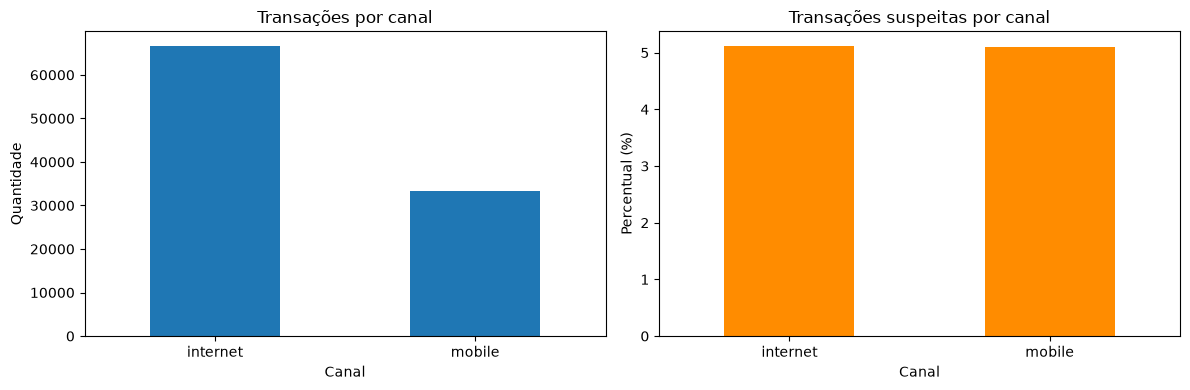

In [42]:
import matplotlib.pyplot as plt

resumo_local = resumo.orderBy("canal").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

resumo_local.plot.bar(
    x="canal",
    y="total_transacoes",
    ax=axes[0],
    legend=False,
    rot=0,
)

axes[0].set_title("Transações por canal")
axes[0].set_xlabel("Canal")
axes[0].set_ylabel("Quantidade")

resumo_local.plot.bar(
    x="canal",
    y="percentual_suspeitas",
    ax=axes[1],
    legend=False,
    rot=0,
    color="darkorange",
)

axes[1].set_title("Transações suspeitas por canal")
axes[1].set_xlabel("Canal")
axes[1].set_ylabel("Percentual (%)")

plt.tight_layout()
plt.show()

### Encerrar a sessão do Notebook no Spark

In [43]:
if globals().get("spark") is not None:
    spark.stop()
    spark = None

print("Sessão do notebook encerrada.")
print("O Spark Connect existente permanece disponível.")

Sessão do notebook encerrada.
O Spark Connect existente permanece disponível.
